# Pipeline MNIST + API FastAPI

**Objetivo:** treinar uma MLP com TensorFlow/Keras usando `sklearn.Pipeline` + `SciKeras`, aplicar calibração (Temperature Scaling), detecção de OOD (Maximum Softmax Probability) e exportar os artefatos prontos para servir em uma API FastAPI.

**Saída deste notebook:**
- `models/mlp_mnist.keras`
- `models/preprocess_pipeline.joblib`
- `models/temperature.json`
- `models/ood_threshold.json`
- `models/metrics.csv`
- `models/confusion_matrix.png`
- Toda a estrutura `app/` da API FastAPI
- `tests/` com testes automatizados


# 1- Instala todas as dependências necessárias 

In [1]:
# %pip install tensorflow==2.15.0 --force-reinstall
# %pip install -q scikeras==0.12.0 fastapi==0.104.1 "uvicorn[standard]==0.24.0" pydantic==2.5.2 pydantic-settings==2.1.0 python-multipart==0.0.6 scikit-learn==1.3.2 scipy==1.11.4 seaborn==0.13.0 matplotlib==3.8.2 joblib==1.3.2 Pillow==10.1.0 python-json-logger==2.0.7 prometheus-client==0.19.0 httpx==0.25.2 pytest==7.4.3 pytest-asyncio==0.21.1 pandas==2.1.4


# 2- Imports, seeds e diretórios do projeto

In [ ]:
# ==========================================================
# Imports, seeds e diretórios do projeto
# ==========================================================
import os, json, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import minimize_scalar
from scipy.ndimage import rotate, shift

import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    roc_auc_score, roc_curve, auc
)
from scikeras.wrappers import KerasClassifier, KerasRegressor
import joblib

# ---------- Reprodutibilidade ----------
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ---------- Diretórios ----------
# Detecta se estamos em notebooks/ ou na raiz do projeto
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

MODELS_DIR    = BASE_DIR / "models"
DATA_DIR      = BASE_DIR / "data"
APP_DIR       = BASE_DIR / "app"
ROUTERS_DIR   = APP_DIR / "routers"
TESTS_DIR     = BASE_DIR / "tests"
NOTEBOOKS_DIR = BASE_DIR / "notebooks"

for d in [MODELS_DIR, DATA_DIR, APP_DIR, ROUTERS_DIR, TESTS_DIR, NOTEBOOKS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("GPU disponível:", tf.config.list_physical_devices("GPU"))
print("BASE_DIR:", BASE_DIR)

# 3- Carregamento dos Dados MNIST

In [ ]:
# ==========================================================
# Carrega o MNIST e divide em treino / validação / teste
# ==========================================================
(x_train_full, y_train_full), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normaliza para [0,1] e readequa para (N, 28, 28, 1)
x_train_full = (x_train_full.astype("float32") / 255.0).reshape(-1, 28, 28, 1)
x_test       = (x_test.astype("float32")       / 255.0).reshape(-1, 28, 28, 1)

# Divisão treino/validação estratificada
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full,
    test_size=0.15,
    random_state=SEED,
    stratify=y_train_full,
)

print(f"Treino:    {x_train.shape} | labels: {y_train.shape}")
print(f"Validação: {x_val.shape}   | labels: {y_val.shape}")
print(f"Teste:     {x_test.shape}  | labels: {y_test.shape}")

KeyboardInterrupt: 

# 4- Visualização de Amostras

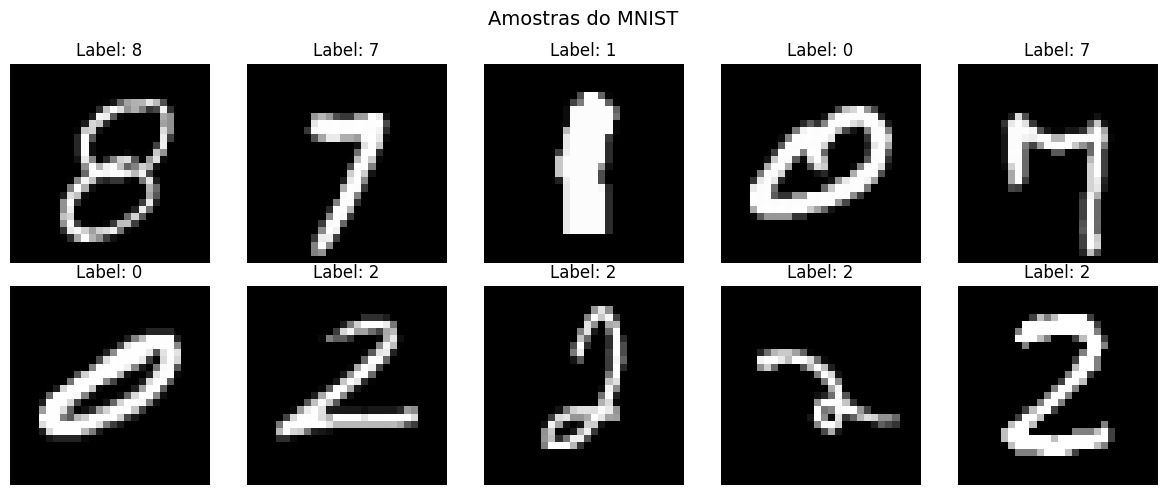

In [ ]:
# Mostra 10 amostras do conjunto de treino
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i].squeeze(), cmap="gray")
    ax.set_title(f"Label: {y_train[i]}")
    ax.axis("off")
plt.suptitle("Amostras do MNIST", fontsize=14)
plt.tight_layout()
plt.show()

# 5- Função de Construção da MLP

In [ ]:
# ==========================================================
# Função que constrói a MLP (compatível com SciKeras)
# ==========================================================
def build_mlp(meta, hidden_1=512, hidden_2=256, dropout=0.3, lr=1e-3):
    """
    Constrói a MLP. O parâmetro `meta` é injetado automaticamente
    pelo SciKeras com n_features_in_ e n_classes_.
    """
    n_features = meta["n_features_in_"]
    n_classes  = meta["n_classes_"]

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(n_features,), name="input"),
        tf.keras.layers.Dense(hidden_1, activation="relu", name="dense_1"),
        tf.keras.layers.Dropout(dropout, name="dropout_1"),
        tf.keras.layers.Dense(hidden_2, activation="relu", name="dense_2"),
        tf.keras.layers.Dropout(dropout, name="dropout_2"),
        # Sem softmax: retornamos logits para calibrar depois
        tf.keras.layers.Dense(n_classes, activation=None, name="logits"),
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=["accuracy"],
    )
    return model

print("✅ build_mlp definida")

✅ build_mlp definida


# 6- Construção do Pipeline Híbrido

In [ ]:
# ==========================================================
# Pipeline híbrido: sklearn.Pipeline + SciKeras
# ==========================================================
keras_clf = KerasClassifier(
    model=build_mlp,
    epochs=30,
    batch_size=128,
    verbose=0,
    random_state=SEED,
    # hiperparâmetros repassados a build_mlp:
    model__hidden_1=512,
    model__hidden_2=256,
    model__dropout=0.3,
    model__lr=1e-3,
    # callbacks:
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="loss", patience=5, restore_best_weights=True, verbose=1
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="loss", factor=0.5, patience=2, min_lr=1e-5, verbose=1
        ),
    ],
)

full_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler",  StandardScaler()),
    ("clf",     keras_clf),
])

print(full_pipeline)

Pipeline(steps=[('imputer', SimpleImputer()), ('scaler', StandardScaler()),
                ('clf',
                 KerasClassifier(batch_size=128, callbacks=[<keras.src.callbacks.EarlyStopping object at 0x0000022A89104D90>, <keras.src.callbacks.ReduceLROnPlateau object at 0x0000022A89107EB0>], epochs=30, model=<function build_mlp at 0x0000022A890475B0>, model__dropout=0.3, model__hidden_1=512, model__hidden_2=256, model__lr=0.001, random_state=42, verbose=0))])


# 7- Treinamento do Pipeline

In [ ]:
# ==========================================================
# Achata imagens e treina o pipeline completo
# ==========================================================
X_train_flat = x_train.reshape(len(x_train), -1)
X_val_flat   = x_val.reshape(len(x_val), -1)
X_test_flat  = x_test.reshape(len(x_test), -1)

print("Treinando... (pode levar alguns minutos)")
full_pipeline.fit(X_train_flat, y_train)

train_acc = full_pipeline.score(X_train_flat, y_train)
val_acc   = full_pipeline.score(X_val_flat,   y_val)
test_acc  = full_pipeline.score(X_test_flat,  y_test)

print(f"\nAcurácia (treino):    {train_acc:.4f}")
print(f"Acurácia (validação): {val_acc:.4f}")
print(f"Acurácia (teste):     {test_acc:.4f}")

Treinando... (pode levar alguns minutos)




Epoch 15: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 30: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Acurácia (treino):    0.9997
Acurácia (validação): 0.9794
Acurácia (teste):     0.9783


# 8- Extração dos Artefatos do Pipeline

In [ ]:
# ==========================================================
# Extrai o pipeline de pré-processamento e o modelo Keras
# ==========================================================
preprocess_pipeline = Pipeline(full_pipeline.steps[:-1])
trained_keras_model = full_pipeline.named_steps["clf"].model_

# Modelo que retorna apenas logits
logits_model = tf.keras.Model(
    inputs=trained_keras_model.input,
    outputs=trained_keras_model.get_layer("logits").output,
)

print("Pré-processamento:", preprocess_pipeline)
print("Modelo Keras:", trained_keras_model.name)

Pré-processamento: Pipeline(steps=[('imputer', SimpleImputer()), ('scaler', StandardScaler())])
Modelo Keras: sequential


# 9- Calibração (Temperature Scaling)

In [ ]:
# ==========================================================
# Temperature Scaling: encontra T que minimiza NLL na validação
# ==========================================================
X_val_prep = preprocess_pipeline.transform(X_val_flat)
logits_val = logits_model.predict(X_val_prep, verbose=0)
y_val_np   = y_val.astype("int64")

def nll_loss(temperature):
    scaled = logits_val / temperature
    max_s  = np.max(scaled, axis=1, keepdims=True)
    exp_s  = np.exp(scaled - max_s)
    probs  = exp_s / np.sum(exp_s, axis=1, keepdims=True)
    correct = probs[np.arange(len(y_val_np)), y_val_np]
    return -np.mean(np.log(correct + 1e-10))

res = minimize_scalar(nll_loss, bounds=(0.1, 5.0), method="bounded")
best_temperature = float(res.x)

with open(MODELS_DIR / "temperature.json", "w") as f:
    json.dump({"temperature": best_temperature}, f)

print(f"Temperatura ótima: {best_temperature:.4f}")
print(f"NLL (T=1):   {nll_loss(1.0):.4f}")
print(f"NLL calib.:  {nll_loss(best_temperature):.4f}")

Temperatura ótima: 2.7388
NLL (T=1):   0.1414
NLL calib.:  0.0859


# 10- Threshold de Detecção OOD

✅ Novo Threshold OOD: -15.0871 (percentil 94)


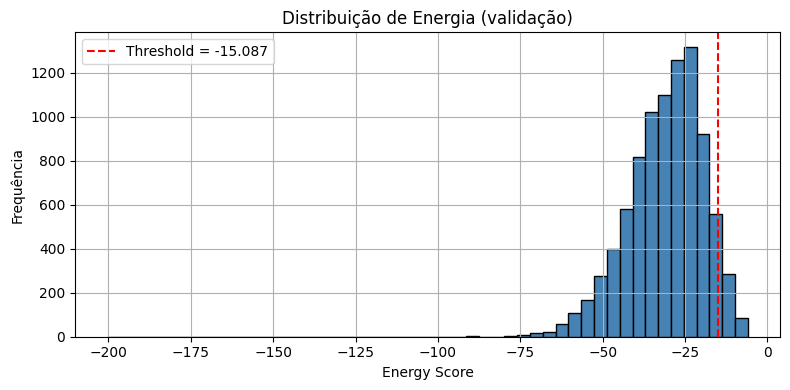

In [ ]:
# ==========================================================
# Define threshold OOD usando ENERGY SCORE (percentil 94)
# ==========================================================
def calculate_energy(logits, T=1.0):
    return -T * tf.reduce_logsumexp(logits / T, axis=1).numpy()

# Calcula a energia no conjunto de validação
energy_val = calculate_energy(logits_val, best_temperature)

# MUDANÇA AQUI: Percentil 94 para aceitar números digitais
OOD_PERCENTILE = 94
energy_threshold = float(np.percentile(energy_val, OOD_PERCENTILE))

# Salva o novo threshold
with open(MODELS_DIR / "ood_threshold.json", "w") as f:
    json.dump({"threshold": energy_threshold, "method": "energy", "percentile": OOD_PERCENTILE}, f)

print(f"✅ Novo Threshold OOD: {energy_threshold:.4f} (percentil {OOD_PERCENTILE})")

# Plota o gráfico
plt.figure(figsize=(8, 4))
plt.hist(energy_val, bins=50, color="steelblue", edgecolor="black")
plt.axvline(energy_threshold, color="red", linestyle="--",
            label=f"Threshold = {energy_threshold:.3f}")
plt.title("Distribuição de Energia (validação)")
plt.xlabel("Energy Score"); plt.ylabel("Frequência")
plt.legend(); plt.grid(True)
plt.tight_layout()
plt.show()

# 11- Teste Rápido de OOD com Ruído

In [ ]:
# Ruído gaussiano puro deve ser detectado como OOD
np.random.seed(SEED)
noise_samples = np.random.rand(500, 28, 28, 1).astype("float32")
noise_flat = noise_samples.reshape(500, -1)
noise_prep = preprocess_pipeline.transform(noise_flat)

logits_noise = logits_model.predict(noise_prep, verbose=0)
energy_noise = calculate_energy(logits_noise, best_temperature)

# Invertemos a regra: se Energy > Threshold, é OOD.
ood_rate = np.mean(energy_noise > energy_threshold)
print(f"Taxa de detecção OOD em ruído puro: {ood_rate*100:.2f}%")

Taxa de detecção OOD em ruído puro: 55.80%


# 12- Métricas no Teste

In [ ]:
# ==========================================================
# Métricas globais no conjunto de teste
# ==========================================================
X_test_prep = preprocess_pipeline.transform(X_test_flat)
logits_test = logits_model.predict(X_test_prep, verbose=0)
probs_test  = tf.nn.softmax(logits_test / best_temperature).numpy()
y_pred      = np.argmax(probs_test, axis=1)

acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average="weighted", zero_division=0)
rec  = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1   = f1_score(y_test, y_pred, average="weighted", zero_division=0)

y_test_bin = label_binarize(y_test, classes=list(range(10)))
roc_auc    = roc_auc_score(y_test_bin, probs_test, average="weighted",
                           multi_class="ovr")

print("=" * 55)
print(f"Acurácia Global:          {acc:.3f}")
print(f"Precisão (ponderada):     {prec:.3f}")
print(f"Recall (ponderado):       {rec:.3f}")
print(f"F1-Score (ponderado):     {f1:.3f}")
print(f"ROC-AUC (OvR, ponderado): {roc_auc:.3f}")
print("=" * 55)

print("\nRelatório por classe:")
print(classification_report(y_test, y_pred, digits=4))

Acurácia Global:          0.978
Precisão (ponderada):     0.978
Recall (ponderado):       0.978
F1-Score (ponderado):     0.978
ROC-AUC (OvR, ponderado): 0.999

Relatório por classe:
              precision    recall  f1-score   support

           0     0.9868    0.9929    0.9898       980
           1     0.9868    0.9912    0.9890      1135
           2     0.9767    0.9767    0.9767      1032
           3     0.9801    0.9772    0.9787      1010
           4     0.9825    0.9695    0.9759       982
           5     0.9764    0.9731    0.9747       892
           6     0.9792    0.9843    0.9818       958
           7     0.9709    0.9728    0.9718      1028
           8     0.9742    0.9682    0.9712       974
           9     0.9685    0.9752    0.9719      1009

    accuracy                         0.9783     10000
   macro avg     0.9782    0.9781    0.9782     10000
weighted avg     0.9783    0.9783    0.9783     10000



# 13- Matriz de Confusão

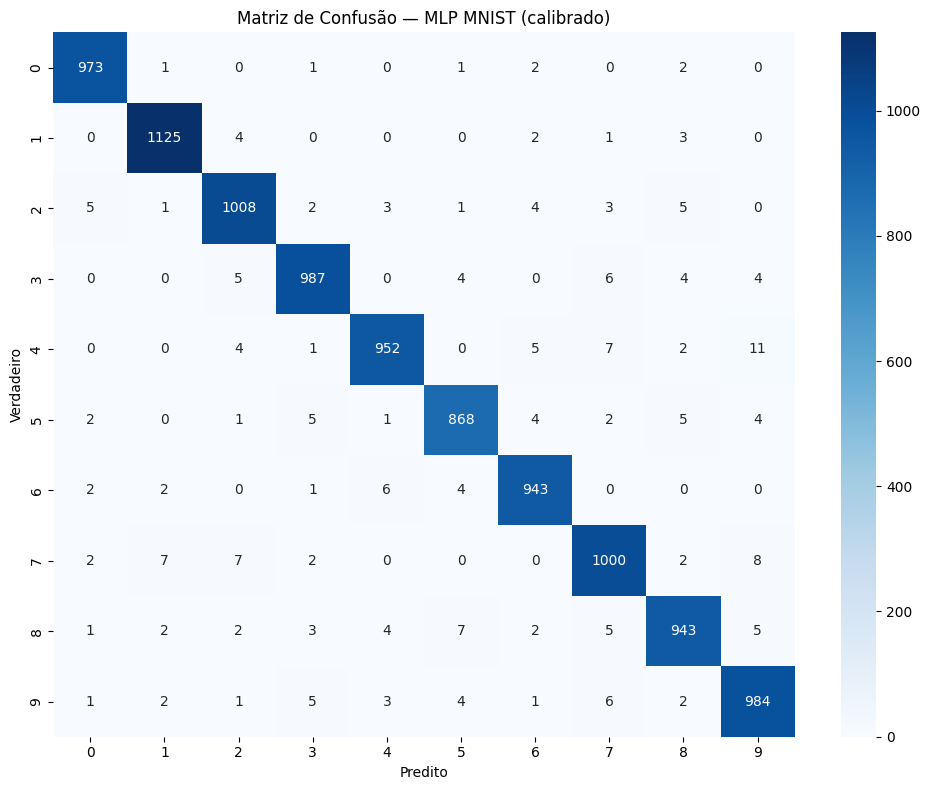

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=range(10), yticklabels=range(10))
plt.title("Matriz de Confusão — MLP MNIST (calibrado)")
plt.xlabel("Predito"); plt.ylabel("Verdadeiro")
plt.tight_layout()
plt.savefig(MODELS_DIR / "confusion_matrix.png", dpi=150)
plt.show()

# 14- Curvas ROC por Classe

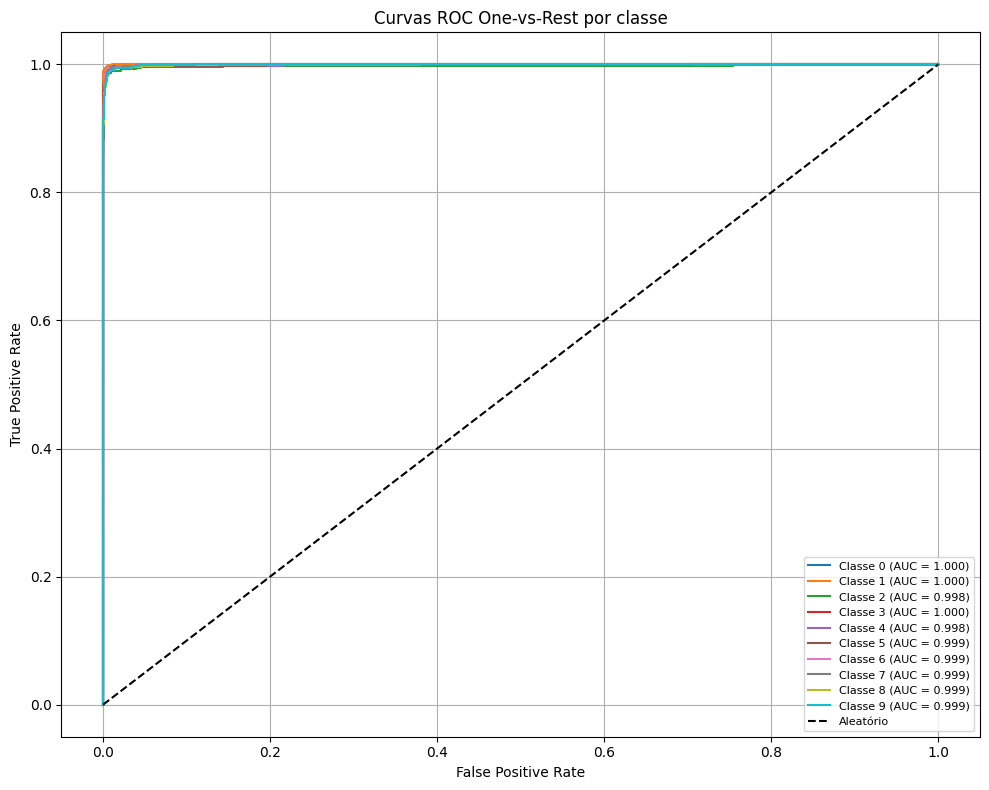

In [ ]:
plt.figure(figsize=(10, 8))
for i in range(10):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], probs_test[:, i])
    plt.plot(fpr, tpr, label=f"Classe {i} (AUC = {auc(fpr, tpr):.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Aleatório")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("Curvas ROC One-vs-Rest por classe")
plt.legend(loc="lower right", fontsize=8); plt.grid(True)
plt.tight_layout()
plt.show()

# 15- Tabela Consolidada

In [ ]:
metrics_table = pd.DataFrame({
    "Métrica": [
        "Acurácia Global", "Precisão Ponderada", "Recall Ponderado",
        "F1-Score Ponderado", "ROC-AUC (OvR, ponderado)"
    ],
    "Valor": [acc, prec, rec, f1, roc_auc],
})
metrics_table["Valor"] = metrics_table["Valor"].round(4)
metrics_table.to_csv(MODELS_DIR / "metrics.csv", index=False)
metrics_table

,Métrica,Valor
0,Acurácia Global,0.9783
1,Precisão Ponderada,0.9783
2,Recall Ponderado,0.9783
3,F1-Score Ponderado,0.9783
4,"ROC-AUC (OvR, ponderado)",0.9992


# 16- Testes de Robustez

In [ ]:
def evaluate_on(x_modified, y_true, name):
    x_flat = x_modified.reshape(len(x_modified), -1)
    # CORREÇÃO: Mantemos em 2D para o predict
    x_prep = preprocess_pipeline.transform(x_flat)
    
    logits = logits_model.predict(x_prep, verbose=0)
    probs  = tf.nn.softmax(logits / best_temperature).numpy()
    preds  = np.argmax(probs, axis=1)
    a = accuracy_score(y_true, preds)
    print(f"{name:<32} Acurácia: {a:.4f}")
    return a

N = 2000
idx = np.random.RandomState(SEED).choice(len(x_test), N, replace=False)
x_sample, y_sample = x_test[idx], y_test[idx]

results = {}
results["Original"] = evaluate_on(x_sample, y_sample, "Original")

# Ruído gaussiano
noise = np.random.normal(0, 0.2, x_sample.shape).astype("float32")
x_noisy = np.clip(x_sample + noise, 0, 1)
results["Ruído gaussiano (σ=0.2)"] = evaluate_on(x_noisy, y_sample, "Ruído gaussiano (σ=0.2)")

# Rotação 15°
x_rot = np.stack([rotate(img.squeeze(), angle=15, reshape=False) for img in x_sample])
x_rot = x_rot[..., np.newaxis].astype("float32")
results["Rotação 15°"] = evaluate_on(x_rot, y_sample, "Rotação 15°")

# Shift
x_shift = np.stack([shift(img.squeeze(), shift=(0, 3)) for img in x_sample])
x_shift = x_shift[..., np.newaxis].astype("float32")
results["Shift (3px direita)"] = evaluate_on(x_shift, y_sample, "Shift (3px direita)")

# Oclusão
x_mask = x_sample.copy()
x_mask[:, 9:19, 9:19, :] = 0
results["Oclusão central 10x10"] = evaluate_on(x_mask, y_sample, "Oclusão central 10x10")

pd.DataFrame(list(results.items()), columns=["Cenário", "Acurácia"]).round(4)

Original                         Acurácia: 0.9770
Ruído gaussiano (σ=0.2)          Acurácia: 0.1060
Rotação 15°                      Acurácia: 0.9120
Shift (3px direita)              Acurácia: 0.5885
Oclusão central 10x10            Acurácia: 0.4540


,Cenário,Acurácia
0,Original,0.9770
1,Ruído gaussiano (σ=0.2),0.1060
2,Rotação 15°,0.9120
3,Shift (3px direita),0.5885
4,Oclusão central 10x10,0.4540


# 17- Salvar Artefatos do Modelo

In [ ]:
# ==========================================================
# Salva artefatos em models/ (produção)
# ==========================================================
joblib.dump(preprocess_pipeline, MODELS_DIR / "preprocess_pipeline.joblib")
trained_keras_model.save(MODELS_DIR / "mlp_mnist.keras")

print("Artefatos em models/:")
for f in sorted(MODELS_DIR.iterdir()):
    print(" -", f.name)

Artefatos em models/:
 - confusion_matrix.png
 - metrics.csv
 - mlp_mnist.keras
 - ood_threshold.json
 - preprocess_pipeline.joblib
 - temperature.json


# 18- Sanity Check dos Artefatos 

In [ ]:
# Recarrega do disco e testa com uma amostra real
_prep  = joblib.load(MODELS_DIR / "preprocess_pipeline.joblib")
_model = tf.keras.models.load_model(MODELS_DIR / "mlp_mnist.keras")
_temp  = json.load(open(MODELS_DIR / "temperature.json"))["temperature"]

_logits = tf.keras.Model(_model.input, _model.get_layer("logits").output)

# CORREÇÃO: Sem reshape para 4D antes do predict
_x = _prep.transform(x_test[0].reshape(1, -1)) 
_l = _logits.predict(_x, verbose=0)
_p = tf.nn.softmax(_l / _temp).numpy()[0]

print("Label verdadeiro:", y_test[0])
print("Predição:", int(np.argmax(_p)))
print("Confiança:", float(np.max(_p)))

Label verdadeiro: 7
Predição: 7
Confiança: 0.9998223185539246


# 19- Criar app/__init__.py e app/config.py

In [ ]:
from pathlib import Path

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
APP_DIR = BASE_DIR / "app"
APP_DIR.mkdir(parents=True, exist_ok=True)

(APP_DIR / "__init__.py").write_text("", encoding="utf-8")

(APP_DIR / "config.py").write_text('''"""
Configurações da aplicação via variáveis de ambiente.
"""
from pathlib import Path
from pydantic_settings import BaseSettings, SettingsConfigDict


class Settings(BaseSettings):
    # CORREÇÃO: Adicionado protected_namespaces=() para silenciar o aviso do model_
    model_config = SettingsConfigDict(env_file=".env", extra="ignore", protected_namespaces=())

    base_dir: Path = Path(__file__).resolve().parent.parent
    model_path: Path = base_dir / "models" / "mlp_mnist.keras"
    preprocess_path: Path = base_dir / "models" / "preprocess_pipeline.joblib"
    temperature_path: Path = base_dir / "models" / "temperature.json"
    ood_threshold_path: Path = base_dir / "models" / "ood_threshold.json"

    max_image_size_mb: int = 5
    max_image_dimension: int = 4096

    binarize_threshold: int = 20
    digit_margin: int = 20

    model_version: str = "1.0.0"
    api_version: str = "1.0.0"
    log_level: str = "INFO"


settings = Settings()
''', encoding="utf-8")

print("✅ app/__init__.py e app/config.py criados")

✅ app/__init__.py e app/config.py criados


# 20- Criar app/schemas.py

In [ ]:
"""
Schemas Pydantic para validação estrita.
"""
from typing import List, Union
from pydantic import BaseModel, Field


class PredictRequest(BaseModel):
    # Evita o aviso do Pydantic v2 com a palavra "model_"
    model_config = {"protected_namespaces": ()}
    
    pixels: List[float] = Field(
        ..., 
        min_length=784, 
        max_length=784,
        description="Lista de 784 valores de pixel (0-255) da imagem 28x28.",
    )


class PredictBase64Request(BaseModel):
    model_config = {"protected_namespaces": ()}
    
    image_base64: str = Field(
        ..., 
        min_length=10,
        description="Imagem PNG/JPEG codificada em base64 (sem o prefixo data:).",
    )


class PredictResponse(BaseModel):
    model_config = {"protected_namespaces": ()}
    
    # ALTERAÇÃO: Aceita um número inteiro (0-9) OU uma string ("Desconhecido")
    predicted_class: Union[int, str] = Field(
        ..., 
        description="Dígito previsto (0-9) ou 'Desconhecido' se a imagem for Out-of-Distribution."
    )
    
    probabilities: List[float] = Field(
        ..., 
        min_length=10, 
        max_length=10,
        description="Probabilidades calibradas para as 10 classes.",
    )
    
    confidence: float = Field(
        ..., 
        ge=0.0, 
        le=1.0, 
        description="Confiança máxima da previsão.",
    )
    
    is_ood: bool = Field(
        ..., 
        description="True se a imagem for considerada fora da distribuição (OOD)."
    )
    
    # NOVO CAMPO: Mensagem amigável explicando o resultado
    message: str = Field(
        default="", 
        description="Mensagem descritiva sobre o resultado da predição."
    )
    
    preprocessed_pixels: List[float] = Field(
        default_factory=list,
        description="Imagem 28x28 (784 valores) após o pré-processamento. Útil para debug.",
    )


class HealthResponse(BaseModel):
    model_config = {"protected_namespaces": ()}
    
    status: str
    model_loaded: bool
    model_version: str
    uptime_seconds: float
    requests_total: int

# 21- Criar app/image_processing.py

In [ ]:
from pathlib import Path

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
APP_DIR = BASE_DIR / "app"
APP_DIR.mkdir(parents=True, exist_ok=True)

(APP_DIR / "image_processing.py").write_text('''"""
Pipeline de pré-processamento de imagens manuscritas para o formato MNIST.
"""
import io
import base64
import logging

import numpy as np
from PIL import Image, ImageOps, UnidentifiedImageError

from app.config import settings

logger = logging.getLogger(__name__)


class ImageProcessingError(ValueError):
    pass


def decode_base64_image(b64_string: str) -> Image.Image:
    if "," in b64_string:
        b64_string = b64_string.split(",", 1)[1]
    try:
        raw = base64.b64decode(b64_string, validate=True)
    except Exception as e:
        raise ImageProcessingError(f"Base64 inválido: {e}")
    return load_image_from_bytes(raw)


def load_image_from_bytes(raw_bytes: bytes) -> Image.Image:
    max_bytes = settings.max_image_size_mb * 1024 * 1024
    if len(raw_bytes) > max_bytes:
        raise ImageProcessingError(
            f"Imagem excede o limite de {settings.max_image_size_mb} MB."
        )
    try:
        img = Image.open(io.BytesIO(raw_bytes))
        img.verify()
        img = Image.open(io.BytesIO(raw_bytes))
    except (UnidentifiedImageError, Exception) as e:
        raise ImageProcessingError(f"Formato de imagem inválido: {e}")
    if max(img.size) > settings.max_image_dimension:
        raise ImageProcessingError(
            f"Dimensão máxima permitida: {settings.max_image_dimension}px."
        )
    return img


def preprocess_image(img: Image.Image) -> np.ndarray:
    img = img.convert("L")
    arr = np.array(img, dtype=np.uint8)
    if arr.mean() > 127:
        img = ImageOps.invert(img)
        arr = np.array(img, dtype=np.uint8)

    arr = np.where(arr > settings.binarize_threshold, arr, 0).astype(np.uint8)

    ys, xs = np.where(arr > settings.binarize_threshold)
    if len(xs) == 0:
        raise ImageProcessingError("Nenhum dígito detectado na imagem.")

    x0, x1 = xs.min(), xs.max()
    y0, y1 = ys.min(), ys.max()
    digit = arr[y0:y1 + 1, x0:x1 + 1]

    h, w = digit.shape
    escala = settings.digit_margin / max(h, w)
    novo_h = max(1, int(round(h * escala)))
    novo_w = max(1, int(round(w * escala)))

    digit_img = Image.fromarray(digit).resize((novo_w, novo_h), Image.LANCZOS)
    digit_arr = np.array(digit_img)

    canvas = np.zeros((28, 28), dtype=np.uint8)
    y_off = (28 - novo_h) // 2
    x_off = (28 - novo_w) // 2
    canvas[y_off:y_off + novo_h, x_off:x_off + novo_w] = digit_arr

    ys, xs = np.where(canvas > settings.binarize_threshold)
    if len(xs) > 0:
        cy = int(ys.mean())
        cx = int(xs.mean())
        canvas = np.roll(canvas, shift=(14 - cy, 14 - cx), axis=(0, 1))

    return (canvas.astype("float32") / 255.0).reshape(28, 28, 1)
''', encoding="utf-8")

print("✅ app/image_processing.py criado")

✅ app/image_processing.py criado


# 23- Criar app/logging_config.py e app/metrics.py

In [ ]:
from pathlib import Path

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
APP_DIR = BASE_DIR / "app"
APP_DIR.mkdir(parents=True, exist_ok=True)

(APP_DIR / "logging_config.py").write_text('''"""
Logging estruturado em JSON.
"""
import logging
import sys
from pythonjsonlogger import jsonlogger


def setup_logging(level: str = "INFO") -> None:
    handler = logging.StreamHandler(sys.stdout)
    formatter = jsonlogger.JsonFormatter(
        "%(asctime)s %(levelname)s %(name)s %(message)s"
    )
    handler.setFormatter(formatter)
    root = logging.getLogger()
    root.handlers = [handler]
    root.setLevel(level.upper())
''', encoding="utf-8")

(APP_DIR / "metrics.py").write_text('''"""
Métricas Prometheus.
"""
from prometheus_client import Counter, Histogram, Gauge

PREDICTIONS_TOTAL = Counter(
    "mnist_predictions_total",
    "Total de predições realizadas",
    ["endpoint", "predicted_class"],
)
PREDICTION_LATENCY = Histogram(
    "mnist_prediction_latency_seconds",
    "Latência da predição",
    ["endpoint"],
)
OOD_TOTAL = Counter("mnist_ood_total", "Total de amostras OOD")
REQUESTS_TOTAL = Gauge("mnist_requests_total", "Total de requisições")
''', encoding="utf-8")

print("✅ app/logging_config.py e app/metrics.py criados")

✅ app/logging_config.py e app/metrics.py criados


# 24- Criar app/services.py

In [ ]:
"""
Camada de serviço: carregamento do modelo e inferência com Energy Score OOD.
"""
import json
import logging

import numpy as np
import tensorflow as tf
import joblib
from PIL import Image

from app.image_processing import preprocess_image

logger = logging.getLogger(__name__)


class ModelService:
    def __init__(
        self,
        model_path: str,
        preprocess_path: str,
        temperature_path: str,
        ood_threshold_path: str,
        model_version: str = "1.0.0",
    ):
        logger.info("Carregando modelo Keras de %s", model_path)
        self.model = tf.keras.models.load_model(model_path)
        
        logger.info("Carregando pipeline de pré-processamento de %s", preprocess_path)
        self.preprocess = joblib.load(preprocess_path)
        self.model_version = model_version

        with open(temperature_path, "r") as f:
            self.temperature = float(json.load(f)["temperature"])
            
        with open(ood_threshold_path, "r") as f:
            self.ood_threshold = float(json.load(f)["threshold"])

        logits_layer = self.model.get_layer("logits")
        self.logits_model = tf.keras.Model(
            inputs=self.model.input,
            outputs=logits_layer.output,
        )
        logger.info(
            "Modelo carregado. T=%.4f, Energy Threshold=%.4f",
            self.temperature, self.ood_threshold,
        )

    def _infer_from_array(self, arr_28x28x1: np.ndarray) -> dict:
        # Achata a imagem para o formato do pipeline sklearn (N, 784)
        flat = arr_28x28x1.reshape(1, -1)
        flat_prep = self.preprocess.transform(flat)

        # Pega os logits (saída da rede neural antes do softmax)
        logits = self.logits_model.predict(flat_prep, verbose=0)
        
        # Calcula as probabilidades (necessário para a resposta JSON)
        probs = tf.nn.softmax(logits / self.temperature, axis=-1).numpy()[0]
        
        # Calcula o Energy Score
        energy = -self.temperature * tf.reduce_logsumexp(logits / self.temperature, axis=-1).numpy()[0]

        # Verifica se é OOD (energia alta)
        is_ood = bool(energy > self.ood_threshold)

        # REGRA DE NEGÓCIO: Se for OOD, oculta a previsão numérica
        if is_ood:
            return {
                "predicted_class": "Desconhecido",
                "probabilities": [float(p) for p in probs],
                "confidence": float(np.max(probs)),
                "is_ood": True,
                "message": "A imagem não parece ser um dígito válido de 0 a 9."
            }

        # Se for um número válido, retorna a classe normalmente
        pred_class = int(np.argmax(probs))
        return {
            "predicted_class": pred_class,
            "probabilities": [float(p) for p in probs],
            "confidence": float(np.max(probs)),
            "is_ood": False,
            "message": f"Dígito {pred_class} reconhecido com sucesso."
        }

    def predict_from_pixels(self, pixels: list) -> dict:
        """Inferência a partir de uma lista de 784 pixels."""
        arr = np.asarray(pixels, dtype=np.float32).reshape(28, 28, 1)
        if arr.max() > 1.0:
            arr = arr / 255.0
        result = self._infer_from_array(arr)
        result["preprocessed_pixels"] = (arr.squeeze() * 255.0).flatten().tolist()
        return result

    def predict_from_image(self, img: Image.Image) -> dict:
        """Inferência a partir de uma imagem PIL."""
        arr = preprocess_image(img)
        result = self._infer_from_array(arr)
        result["preprocessed_pixels"] = (arr.squeeze() * 255.0).flatten().tolist()
        return result

# 25- Criar app/routers

In [ ]:
from pathlib import Path

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
APP_DIR = BASE_DIR / "app"
ROUTERS_DIR = APP_DIR / "routers"
ROUTERS_DIR.mkdir(parents=True, exist_ok=True)

(ROUTERS_DIR / "__init__.py").write_text("", encoding="utf-8")

(ROUTERS_DIR / "health.py").write_text('''"""
Rota de monitoramento de saúde.
"""
import time
from fastapi import APIRouter, Request
from app.schemas import HealthResponse

router = APIRouter()


@router.get("/health", response_model=HealthResponse, tags=["Monitoramento"])
async def health(request: Request) -> HealthResponse:
    service = getattr(request.app.state, "model_service", None)
    start_time = getattr(request.app.state, "start_time", time.time())
    return HealthResponse(
        status="ok" if service is not None else "degraded",
        model_loaded=service is not None,
        model_version=service.model_version if service else "unknown",
        uptime_seconds=round(time.time() - start_time, 2),
        requests_total=getattr(request.app.state, "requests_total", 0),
    )
''', encoding="utf-8")

(ROUTERS_DIR / "predict.py").write_text('''"""
Rota de inferência via JSON (784 pixels).
"""
from fastapi import APIRouter, HTTPException, Request
from app.schemas import PredictRequest, PredictResponse
from app.metrics import PREDICTIONS_TOTAL, OOD_TOTAL

router = APIRouter()


@router.post(
    "/v1/predict",
    response_model=PredictResponse,
    summary="Classifica a partir de 784 pixels (JSON)",
    tags=["Inferência"],
)
async def predict(request: Request, payload: PredictRequest) -> PredictResponse:
    service = getattr(request.app.state, "model_service", None)
    if service is None:
        raise HTTPException(status_code=503, detail="Modelo não está carregado.")

    try:
        result = service.predict_from_pixels(payload.pixels)
        PREDICTIONS_TOTAL.labels(
            endpoint="/v1/predict",
            predicted_class=str(result["predicted_class"]),
        ).inc()
        if result["is_ood"]:
            OOD_TOTAL.inc()
        return PredictResponse(**result)
    except ValueError as e:
        raise HTTPException(status_code=400, detail=f"Erro de validação: {e}")
    except Exception as e:
        raise HTTPException(status_code=500, detail=f"Erro interno: {e}")
''', encoding="utf-8")

(ROUTERS_DIR / "predict_image.py").write_text('''"""
Rota de inferência via upload de imagem ou base64.
"""
import logging

from fastapi import APIRouter, File, HTTPException, Request, UploadFile

from app.image_processing import (
    ImageProcessingError,
    decode_base64_image,
    load_image_from_bytes,
)
from app.schemas import PredictBase64Request, PredictResponse
from app.metrics import PREDICTIONS_TOTAL, OOD_TOTAL

logger = logging.getLogger(__name__)
router = APIRouter()


@router.post(
    "/v1/predict/image",
    response_model=PredictResponse,
    summary="Classifica a partir de upload de imagem",
    tags=["Inferência"],
)
async def predict_from_upload(
    request: Request,
    file: UploadFile = File(..., description="PNG/JPEG da imagem manuscrita."),
) -> PredictResponse:
    service = getattr(request.app.state, "model_service", None)
    if service is None:
        raise HTTPException(status_code=503, detail="Modelo não está carregado.")

    allowed = {"image/png", "image/jpeg", "image/jpg", "image/webp"}
    if file.content_type not in allowed:
        raise HTTPException(
            status_code=415,
            detail=f"Content-Type não suportado: {file.content_type}.",
        )

    try:
        raw = await file.read()
        img = load_image_from_bytes(raw)
        result = service.predict_from_image(img)

        PREDICTIONS_TOTAL.labels(
            endpoint="/v1/predict/image",
            predicted_class=str(result["predicted_class"]),
        ).inc()
        if result["is_ood"]:
            OOD_TOTAL.inc()

        return PredictResponse(**result)

    except ImageProcessingError as e:
        raise HTTPException(status_code=422, detail=str(e))
    except Exception as e:
        logger.exception("Erro inesperado na inferência")
        raise HTTPException(status_code=500, detail=f"Erro interno: {e}")


@router.post(
    "/v1/predict/base64",
    response_model=PredictResponse,
    summary="Classifica a partir de imagem em base64",
    tags=["Inferência"],
)
async def predict_from_base64(
    request: Request,
    payload: PredictBase64Request,
) -> PredictResponse:
    service = getattr(request.app.state, "model_service", None)
    if service is None:
        raise HTTPException(status_code=503, detail="Modelo não está carregado.")

    try:
        img = decode_base64_image(payload.image_base64)
        result = service.predict_from_image(img)

        PREDICTIONS_TOTAL.labels(
            endpoint="/v1/predict/base64",
            predicted_class=str(result["predicted_class"]),
        ).inc()
        if result["is_ood"]:
            OOD_TOTAL.inc()

        return PredictResponse(**result)

    except ImageProcessingError as e:
        raise HTTPException(status_code=422, detail=str(e))
    except Exception as e:
        logger.exception("Erro inesperado na inferência (base64)")
        raise HTTPException(status_code=500, detail=f"Erro interno: {e}")
''', encoding="utf-8")

print("✅ app/routers/ criados")

✅ app/routers/ criados


# 26- Criar app/main.py

In [ ]:
from pathlib import Path

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
APP_DIR = BASE_DIR / "app"
APP_DIR.mkdir(parents=True, exist_ok=True)

(APP_DIR / "main.py").write_text('''"""
Ponto de entrada da aplicação FastAPI.
"""
import time
from contextlib import asynccontextmanager

from fastapi import FastAPI
from fastapi.middleware.cors import CORSMiddleware
from prometheus_client import make_asgi_app

from app.config import settings
from app.logging_config import setup_logging
from app.routers import health, predict, predict_image
from app.services import ModelService


@asynccontextmanager
async def lifespan(app: FastAPI):
    setup_logging(settings.log_level)
    app.state.start_time = time.time()
    app.state.requests_total = 0

    app.state.model_service = ModelService(
        model_path=str(settings.model_path),
        preprocess_path=str(settings.preprocess_path),
        temperature_path=str(settings.temperature_path),
        ood_threshold_path=str(settings.ood_threshold_path),
        model_version=settings.model_version,
    )
    yield
    app.state.model_service = None


app = FastAPI(
    title="MNIST Classifier API",
    description="Classificação de dígitos manuscritos com OOD e calibração.",
    version=settings.api_version,
    lifespan=lifespan,
)

app.add_middleware(
    CORSMiddleware,
    allow_origins=["*"],
    allow_methods=["*"],
    allow_headers=["*"],
)

app.include_router(health.router)
app.include_router(predict.router)
app.include_router(predict_image.router)
app.mount("/metrics", make_asgi_app())


@app.get("/", tags=["Root"])
async def root():
    return {
        "message": "MNIST Classifier API",
        "docs": "/docs",
        "health": "/health",
        "predict_json": "/v1/predict",
        "predict_image": "/v1/predict/image",
        "predict_base64": "/v1/predict/base64",
        "metrics": "/metrics",
    }
''', encoding="utf-8")

print("✅ app/main.py criado")

✅ app/main.py criado


# 27- Criar os Testes (tests/)

In [ ]:
from pathlib import Path

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TESTS_DIR = BASE_DIR / "tests"
TESTS_DIR.mkdir(parents=True, exist_ok=True)

(TESTS_DIR / "__init__.py").write_text("", encoding="utf-8")

(TESTS_DIR / "test_api.py").write_text('''"""Testes da API com FastAPI TestClient."""
from fastapi.testclient import TestClient
from app.main import app

client = TestClient(app)


def test_health():
    r = client.get("/health")
    assert r.status_code == 200
    assert r.json()["model_loaded"] is True


def test_predict_valid():
    r = client.post("/v1/predict", json={"pixels": [0.0] * 784})
    assert r.status_code == 200
    body = r.json()
    assert 0 <= body["predicted_class"] <= 9
    assert len(body["probabilities"]) == 10


def test_predict_invalid_length():
    r = client.post("/v1/predict", json={"pixels": [0.0] * 10})
    assert r.status_code == 422
''', encoding="utf-8")

(TESTS_DIR / "test_services.py").write_text('''"""Testes unitários da camada de serviço."""
from pathlib import Path
from app.services import ModelService

MODELS = Path(__file__).resolve().parent.parent / "models"


def _service():
    return ModelService(
        model_path=str(MODELS / "mlp_mnist.keras"),
        preprocess_path=str(MODELS / "preprocess_pipeline.joblib"),
        temperature_path=str(MODELS / "temperature.json"),
        ood_threshold_path=str(MODELS / "ood_threshold.json"),
    )


def test_predict_returns_dict():
    service = _service()
    result = service.predict_from_pixels([0.0] * 784)
    assert len(result["probabilities"]) == 10
    assert abs(sum(result["probabilities"]) - 1.0) < 1e-4
''', encoding="utf-8")

(TESTS_DIR / "test_image_processing.py").write_text('''"""Testes do pipeline de pré-processamento de imagem."""
import numpy as np
from PIL import Image
from app.image_processing import preprocess_image, load_image_from_bytes


def _fake_digit_image():
    arr = np.zeros((28, 28), dtype=np.uint8)
    arr[10:18, 12:16] = 255
    return Image.fromarray(arr, mode="L")


def test_preprocess_shape_and_range():
    out = preprocess_image(_fake_digit_image())
    assert out.shape == (28, 28, 1)
    assert 0.0 <= out.min() and out.max() <= 1.0


def test_load_invalid_bytes():
    try:
        load_image_from_bytes(b"nao-e-imagem")
        assert False
    except Exception:
        pass
''', encoding="utf-8")

print("✅ tests/ criados")

✅ tests/ criados


# 28- Verificação Final e Teste da API

In [ ]:
import sys
from pathlib import Path
import numpy as np
import tensorflow as tf

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MODELS_DIR = BASE_DIR / "models"

if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

# Limpa o cache de imports
for mod in ["app.main", "app.services", "app.schemas", "app.config",
            "app.routers.health", "app.routers.predict", "app.routers.predict_image"]:
    if mod in sys.modules:
        del sys.modules[mod]

# ---------------------------------------------------------
# CORREÇÃO 1: Verificar se o modelo realmente foi salvo em disco
# ---------------------------------------------------------
if not (MODELS_DIR / "mlp_mnist.keras").exists():
    print("❌ ERRO: O arquivo models/mlp_mnist.keras não existe.")
    print("Você precisa rodar os Blocos 1 até 18 (treinamento e salvamento) antes de testar a API.")
else:
    from fastapi.testclient import TestClient
    from app.main import app

    # ---------------------------------------------------------
    # CORREÇÃO 2: Usar 'with' para ativar o lifespan (carregar modelo)
    # ---------------------------------------------------------
    with TestClient(app) as client:
        
        # 1) Health
        r = client.get("/health")
        print("GET /health ->", r.status_code)
        print(r.json())
        
        if not r.json()["model_loaded"]:
            print("⚠️ O modelo não carregou. Verifique os logs de erro acima.")

        # 2) Predict
        # CORREÇÃO 3: Recuperar x_test se ele tiver sido apagado da memória
        if 'x_test' not in globals():
            print("\nBaixando amostra do MNIST novamente (pois o Kernel foi reiniciado)...")
            (_, _), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
            x_test = (x_test.astype("float32") / 255.0).reshape(-1, 28, 28, 1)

        sample_pixels = (x_test[0].squeeze().flatten() * 255.0).tolist()
        r = client.post("/v1/predict", json={"pixels": sample_pixels})
        
        if r.status_code == 200:
            print("\nPOST /v1/predict ->", r.status_code)
            print("Label verdadeiro:", y_test[0])
            print("Predição:", r.json()["predicted_class"])
            print("Confiança:", round(r.json()["confidence"], 4))
        else:
            print("\nPOST /v1/predict ->", r.status_code, r.text)

        # 3) Payload inválido -> 422
        r = client.post("/v1/predict", json={"pixels": [0.0] * 10})
        print("\nPOST /v1/predict (inválido) ->", r.status_code)

{"asctime": "2026-10-26 19:47:17,080", "levelname": "INFO", "name": "app.services", "message": "Carregando modelo Keras de C:\\Users\\lapri\\OneDrive\\Desktop\\SCTEC- MEMO\\PROYECTO FINAL\\projeto-mnist-api\\models\\mlp_mnist.keras"}
{"asctime": "2026-10-26 19:47:17,520", "levelname": "INFO", "name": "app.services", "message": "Carregando pipeline de pr\u00e9-processamento de C:\\Users\\lapri\\OneDrive\\Desktop\\SCTEC- MEMO\\PROYECTO FINAL\\projeto-mnist-api\\models\\preprocess_pipeline.joblib"}
{"asctime": "2026-10-26 19:47:17,520", "levelname": "INFO", "name": "app.services", "message": "Modelo carregado. T=2.7388, Energy Threshold=-22.8099"}
{"asctime": "2026-10-26 19:47:17,536", "levelname": "INFO", "name": "httpx", "message": "HTTP Request: GET http://testserver/health \"HTTP/1.1 200 OK\""}
GET /health -> 200
{'status': 'ok', 'model_loaded': True, 'model_version': '1.0.0', 'uptime_seconds': 0.44, 'requests_total': 0}
{"asctime": "2026-10-26 19:47:17,723", "levelname": "INFO", "nam